# 07 — The SLM Training Lifecycle, End to End
### From raw text to a trained, saved and quantized language model, in about a minute on a laptop

> **Learning objective:** Walk through *every* stage of building a language model from scratch (data collection, cleaning, deduplication, tokenization, dataset construction, architecture design, initialization, pretraining, evaluation, improvement, fine-tuning, saving and quantization) by doing each one ourselves, at miniature scale.

Notebooks 01–06 built the pieces one at a time: the Transformer's forward pass (01), tokenization (02), corpus preparation (03), training sequences (04), the language-modeling objective (05), and a trainable PyTorch model (06). In 06, `loss.backward()` and `torch.optim` did the learning for us.

This capstone runs the **whole lifecycle in one place** and opens up the parts PyTorch hid: we write the backward pass and the AdamW optimizer by hand, verify the gradients numerically, and schedule the learning rate. We then add the training-workflow pieces the earlier notebooks didn't cover: **checkpointing the best model, diagnosing overfitting, fine-tuning on a new domain, saving and reloading a model artifact, and int8 quantization**.

### What this notebook is (and is not)

- Everything is written in **NumPy**, including the backward pass and the optimizer, so no step is hidden inside a framework.
- The model is a small **character-level neural language model**: a context window of characters, an embedding table, a hidden layer and a vocabulary projection (the classic design of Bengio et al., 2003). It is not a Transformer yet. Using a simpler network keeps the hand-written gradients short enough to read, while every *lifecycle* stage stays exactly the same as for a real SLM.
- The corpus is a few kilobytes of text written for this notebook. Real pretraining corpora are billions of tokens. The *procedures* are the point here, not the scale.

### The lifecycle we will follow

```text
 1. Data collection        ->  raw documents from several "sources"
 2. Data preprocessing     ->  cleaning, quality filtering, deduplication
 3. Tokenization           ->  a character-level tokenizer with special tokens
 4. Tokenized dataset      ->  train/validation split, (context, next-token) pairs
 5. Architecture design    ->  a config and a parameter count
 6. Initialization         ->  why the initial loss should be about log(V)
 7. Pretraining            ->  forward, backward, gradient check, AdamW, LR schedule
 8. Evaluation             ->  loss, perplexity, baselines, samples
 9. Analyze and improve    ->  a context-length experiment and error analysis
10. Post-training          ->  fine-tuning on a new domain, and forgetting
11. Inference and deploy   ->  decoding, save/load, int8 quantization, throughput
12. Recap                  ->  how each stage maps to the rest of this repository
```

### Imports

In [2]:
import hashlib
import html
import json
import math
import re
import tempfile
import time
import unicodedata
from dataclasses import dataclass, asdict
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.set_printoptions(precision=4, suppress=True)
pd.set_option("display.precision", 4)
pd.set_option("display.max_colwidth", 70)

SEED = 1337
rng = np.random.default_rng(SEED)

print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)

NumPy: 2.4.6
Pandas: 3.1.1

## 1. Data collection

A real pretraining corpus is assembled from many sources: books, encyclopedias, educational material, code, filtered web pages. Every source arrives in its own format and with its own problems.

We simulate that. Our "crawl" contains short educational paragraphs about the natural world, plus the kinds of junk every real crawl contains:

- HTML markup and HTML entities
- an exact copy of a document
- a copy that differs only in whitespace, capitalization or typography
- a *near* duplicate, with one word changed
- spam, and a document that is mostly numbers
- a document too short to be useful

In [3]:
raw_documents = [
    ("encyclopedia", "The sun rises in the east and sets in the west. Each morning its light returns, and each evening the sky turns orange, then purple, then dark."),
    ("encyclopedia", "The moon has no light of its own. It reflects the light of the sun, and its shape seems to change through the month as we see more or less of its bright side."),
    ("encyclopedia", "Rain begins as water that rises from oceans, lakes and rivers. High in the sky the water vapour cools, forms clouds, and falls back to the ground as rain or snow."),
    ("textbook",     "Plants use sunlight, water and air to make their own food. This process is called photosynthesis, and it releases the oxygen that animals need to breathe."),
    ("textbook",     "Bees visit flowers to collect nectar. As they move from flower to flower, they carry pollen with them, which helps the plants make seeds and fruit."),
    ("textbook",     "A river starts small, often as a spring in the hills. It grows as streams join it, and it carries water, sand and stones all the way to the sea."),
    ("encyclopedia", "Trees lose their leaves in autumn. The days grow shorter, the air grows colder, and the trees rest through the winter until spring brings warmth again."),
    ("encyclopedia", "The ocean covers most of the surface of the earth. Its water is salty, its depths are dark and cold, and it is home to fish, whales and countless tiny creatures."),
    ("web",          "Stars are distant suns. On a clear night far from city lights, you can see thousands of them, and the pale band of the milky way stretching across the sky."),
    ("web",          "Wind is moving air. When the sun warms the ground, the air above it rises, and cooler air rushes in to take its place. That movement is the wind we feel."),
    ("textbook",     "Mountains form over millions of years as the plates of the earth push against each other. Wind, rain and ice slowly wear them down again."),
    ("web",          "Birds build nests in the spring. They gather twigs, grass and feathers, and they sing in the early morning to mark their place and to call to each other."),
    ("textbook",     "Snow falls when the air is cold enough for water to freeze before it reaches the ground. Each snowflake grows from a tiny crystal of ice high in a cloud."),
    ("encyclopedia", "The seasons change because the earth is tilted. As it travels around the sun, first one half and then the other leans toward the light and grows warmer."),
    ("web",          "Frogs begin life in the water as tadpoles. They breathe with gills and swim with a tail, and over a few weeks they grow legs and climb out onto the land."),
    ("textbook",     "Clouds are made of tiny drops of water or small crystals of ice. They float because the drops are so light that rising air holds them up in the sky."),
    ("encyclopedia", "The desert receives very little rain. Its plants store water in thick stems and leaves, and its animals rest in the shade through the heat of the day."),
    ("web",          "Lightning is a giant spark of electricity in the sky. It heats the air so quickly that the air expands with a crack, and that sound is the thunder we hear."),
    ("textbook",     "Soil is made of broken rock, water, air and the remains of plants and animals. Worms and tiny creatures mix it, and plants send their roots down into it."),
    ("encyclopedia", "The tide rises and falls twice each day. The pull of the moon draws the water of the ocean toward it, and the shore is covered and uncovered again."),
    ("textbook",     "Ants live together in large colonies. Each ant has a job: some gather food, some care for the young, and some guard the nest from other insects."),
    ("web",          "A rainbow appears when sunlight shines through drops of rain. Each drop bends the light and splits it into red, orange, yellow, green, blue and violet."),
    ("encyclopedia", "Forests are home to many kinds of plants and animals. The tall trees shade the ground, and the fallen leaves turn slowly into rich, dark soil."),
    ("textbook",     "Water can be a solid, a liquid or a gas. When ice is warmed it melts into water, and when water is heated it turns into steam and rises into the air."),
    ("web",          "Owls hunt at night. Their large eyes gather the faint light of the moon and the stars, and their soft feathers let them fly without a sound."),
    ("encyclopedia", "The earth turns once each day. As it turns, half of the world faces the sun and has day, while the other half faces away and has night."),
    ("textbook",     "Seeds need water, warmth and air to grow. A small root pushes down into the soil, a green shoot pushes up toward the light, and a new plant begins."),
    ("web",          "Whales are the largest animals in the ocean. They breathe air like we do, so they rise to the surface to breathe before they dive deep again."),
    ("encyclopedia", "Lakes form where water collects in a low place in the land. Rivers and rain fill them, and many lakes are home to fish, birds and water plants."),
    ("textbook",     "Fish breathe with gills. As water flows over the gills, the fish takes in the oxygen that is in the water, and then the water flows out again."),
    ("web",          "Butterflies begin life as small eggs on a leaf. A caterpillar hatches, eats and grows, then rests in a case until it comes out with bright wings."),
    ("encyclopedia", "Fog is a cloud that touches the ground. It forms on cool, still mornings when the air near the ground is full of water and the light is soft and grey."),
    ("textbook",     "The sun is a star. It is much closer to us than the other stars, which is why it looks so large and bright and why it warms the whole earth."),
    ("web",          "Ice covers the land and the sea near the poles. In the long winter the sun barely rises, and in the short summer it hardly sets at all."),
    ("encyclopedia", "Caves form when water slowly wears away rock under the ground. Drops of water that fall from the roof leave behind stone, and the cave grows over time."),
    ("textbook",     "Animals that sleep through the winter are said to hibernate. They eat a lot in autumn, find a safe place, and rest until the warm days of spring return."),
    # ---- the junk every real crawl contains ----
    ("web",          "<html><body><p>The moon has no light of its own. It reflects the light of the sun,&nbsp;and its shape seems to change through the month as we see more or less of its bright side.</p></body></html>"),
    ("encyclopedia", "The sun rises in the east and sets in the west. Each morning its light returns, and each evening the sky turns orange, then purple, then dark."),
    ("web",          "BEES visit flowers   to collect nectar.\n\nAs they move from flower to flower,\tthey carry pollen with them, which helps the plants make seeds and fruit."),
    ("web",          "Birds build nests in the spring. They gather twigs, grass and feathers, and they sing in the early morning to mark their place and to call to one another."),
    ("web",          "BUY NOW!!! click here click here click here $$$ best price best price best price"),
    ("web",          "order 1234 5678 9012 3456 7890 1111 2222 3333 4444 5555"),
    ("web",          "ok"),
    ("textbook",     "Ｔｈｅ desert receives very little rain. Its plants store water in thick stems and leaves, and its animals rest in the shade through the heat of the day."),
]

documents = pd.DataFrame(raw_documents, columns=["source", "raw_text"])
documents.insert(0, "doc_id", [f"doc{i:02d}" for i in range(len(documents))])
documents["raw_chars"] = documents["raw_text"].str.len()

print("Documents collected:", len(documents))
print("Total raw characters:", documents["raw_chars"].sum())
display(documents.groupby("source").agg(documents=("doc_id", "count"), characters=("raw_chars", "sum")))

Documents collected: 44
Total raw characters: 6264

,documents,characters
source,,
encyclopedia,14,2086
textbook,14,2060
web,16,2118


## 2. Data preprocessing

Raw text is never ready for training. Preprocessing has three jobs:

1. **Cleaning**: remove markup and normalize the text so that equivalent text is encoded identically.
2. **Quality filtering**: drop documents that would teach the model something we don't want.
3. **Deduplication**: remove repeated content, which wastes compute, inflates evaluation scores and encourages memorization.

### 2a. Cleaning and normalization

Every normalization choice is a trade-off:

- **Lowercasing** shrinks the vocabulary (good for a tiny model) but throws away information. Production LLM tokenizers usually keep case.
- **Unicode normalization (NFKC)** and mapping typographic quotes to plain ones merge characters that look the same but have different code points.
- **Whitespace collapsing** turns tabs, newlines and repeated spaces into single spaces.

In [4]:
TAG_PATTERN = re.compile(r"<[^>]+>")
WHITESPACE_PATTERN = re.compile(r"\s+")
TYPOGRAPHY = str.maketrans({"‘": "'", "’": "'", "“": '"', "”": '"', "–": "-", "—": "-"})


def clean_text(text):
    text = TAG_PATTERN.sub(" ", text)            # strip HTML tags
    text = html.unescape(text)                   # &nbsp; -> non-breaking space, &amp; -> &
    text = unicodedata.normalize("NFKC", text)   # non-breaking space -> space, etc.
    text = text.translate(TYPOGRAPHY)            # curly quotes -> straight quotes
    text = text.lower()
    text = WHITESPACE_PATTERN.sub(" ", text).strip()
    return text


documents["clean_text"] = documents["raw_text"].map(clean_text)

examples_to_show = documents.iloc[[-8, -6, -1]]   # the HTML, whitespace and full-width copies
for row in examples_to_show.itertuples():
    doc_id = row.doc_id
    print(f"{doc_id} BEFORE: {row.raw_text[:90]!r}")
    print(f"{doc_id} AFTER:  {row.clean_text[:90]!r}\n")

doc36 BEFORE: '<html><body><p>The moon has no light of its own. It reflects the light of the sun,&nbsp;an'
doc36 AFTER:  'the moon has no light of its own. it reflects the light of the sun, and its shape seems to'

doc38 BEFORE: 'BEES visit flowers   to collect nectar.\n\nAs they move from flower to flower,\tthey carry po'
doc38 AFTER:  'bees visit flowers to collect nectar. as they move from flower to flower, they carry polle'

doc43 BEFORE: 'Ｔｈｅ desert receives very\xa0little rain. Its plants store water in thick stems and leaves, an'
doc43 AFTER:  'the desert receives very little rain. its plants store water in thick stems and leaves, an'

### 2b. Quality filtering

Real pipelines use many heuristics, and often trained classifiers. We implement three classic heuristic rules:

| Rule | Catches |
|:--|:--|
| minimum length | fragments with too little content to learn from |
| minimum fraction of letters | tables of numbers, codes, encoding garbage |
| minimum fraction of *unique* words | spam and boilerplate that repeat themselves |

The thresholds are judgement calls. Strict thresholds throw away good data, and loose ones let junk through.

In [5]:
MIN_CHARS = 40
MIN_LETTER_FRACTION = 0.6
MIN_UNIQUE_WORD_FRACTION = 0.5


def quality_issues(text):
    issues = []
    if len(text) < MIN_CHARS:
        issues.append(f"shorter than {MIN_CHARS} chars")
    letters = sum(ch.isalpha() for ch in text)
    if letters / max(len(text), 1) < MIN_LETTER_FRACTION:
        issues.append(f"letters < {MIN_LETTER_FRACTION:.0%}")
    words = text.split()
    if words and len(set(words)) / len(words) < MIN_UNIQUE_WORD_FRACTION:
        issues.append(f"unique words < {MIN_UNIQUE_WORD_FRACTION:.0%}")
    return issues


documents["quality_issues"] = documents["clean_text"].map(quality_issues)
flagged = documents[documents["quality_issues"].str.len() > 0]
display(flagged[["doc_id", "clean_text", "quality_issues"]])

,doc_id,clean_text,quality_issues
40,doc40,buy now!!! click here click here click here $$$ best price best pr...,[unique words < 50%]
41,doc41,order 1234 5678 9012 3456 7890 1111 2222 3333 4444 5555,[letters < 60%]
42,doc42,ok,[shorter than 40 chars]


### 2c. Deduplication: exact and near-duplicate

**Exact deduplication** hashes the *cleaned* text. Two documents that differ only in markup, case or whitespace become identical after cleaning, so they get the same hash.

**Near-duplicate detection** catches documents that are almost the same. We break each document into overlapping 5-character **shingles** and compare documents using **Jaccard similarity**:

$$
J(A, B) = \frac{|A \cap B|}{|A \cup B|}
$$

Comparing every pair is $O(n^2)$. That's fine for a few dozen documents and hopeless for billions, which is why production systems approximate Jaccard similarity with **MinHash** and **locality-sensitive hashing**. We cover them in Module 02.

In [6]:
NEAR_DUPLICATE_THRESHOLD = 0.8


def shingles(text, n=5):
    return {text[i:i + n] for i in range(len(text) - n + 1)}


def jaccard(a, b):
    return len(a & b) / len(a | b)


decisions, reasons = [], []
seen_hashes = {}   # hash -> doc_id
kept = []          # (doc_id, shingle set)

for row in documents.itertuples():
    if row.quality_issues:
        decisions.append("dropped")
        reasons.append("quality: " + "; ".join(row.quality_issues))
        continue

    digest = hashlib.sha256(row.clean_text.encode("utf-8")).hexdigest()
    if digest in seen_hashes:
        decisions.append("dropped")
        reasons.append(f"exact duplicate of {seen_hashes[digest]}")
        continue

    doc_shingles = shingles(row.clean_text)
    best_id, best_sim = None, 0.0
    for other_id, other_shingles in kept:
        sim = jaccard(doc_shingles, other_shingles)
        if sim > best_sim:
            best_id, best_sim = other_id, sim
    if best_sim >= NEAR_DUPLICATE_THRESHOLD:
        decisions.append("dropped")
        reasons.append(f"near duplicate of {best_id} (Jaccard = {best_sim:.2f})")
        continue

    seen_hashes[digest] = row.doc_id
    kept.append((row.doc_id, doc_shingles))
    decisions.append("kept")
    reasons.append("")

documents["decision"] = decisions
documents["reason"] = reasons

display(documents.loc[documents["decision"] == "dropped", ["doc_id", "source", "reason"]])

clean_docs = documents[documents["decision"] == "kept"].reset_index(drop=True)
print(f"Kept {len(clean_docs)} of {len(documents)} documents "
      f"({clean_docs['clean_text'].str.len().sum()} of {documents['raw_chars'].sum()} characters).")

,doc_id,source,reason
36,doc36,web,exact duplicate of doc01
37,doc37,encyclopedia,exact duplicate of doc00
38,doc38,web,exact duplicate of doc04
39,doc39,web,near duplicate of doc11 (Jaccard = 0.87)
40,doc40,web,quality: unique words < 50%
41,doc41,web,quality: letters < 60%
42,doc42,web,quality: shorter than 40 chars
43,doc43,textbook,exact duplicate of doc16


Kept 36 of 44 documents (5335 of 6264 characters).

Every piece of junk was caught, and each for the reason we expected:

- the HTML copy, the whitespace/case copy and the full-width-Unicode copy became **exact duplicates** after cleaning
- the copy with one changed word was caught as a **near duplicate**
- spam, the number table and the fragment failed the **quality rules**

**Lesson:** cleaning *before* hashing turns many near-duplicates into exact duplicates, which are much cheaper to detect.

### 2d. Train/validation split, by document

We hold out some documents for **validation**: text the model never trains on, which we use to measure generalization.

We split **by document, not by character position**. If we cut one document in half and trained on the first half, the validation half would share topic, vocabulary and phrasing with the training data, and our validation score would be optimistic. This is a small-scale version of a real problem called **data contamination**.

In [7]:
n_val = 5
order = rng.permutation(len(clean_docs))
val_index, train_index = order[:n_val], order[n_val:]

train_texts = clean_docs.loc[sorted(train_index), "clean_text"].tolist()
val_texts = clean_docs.loc[sorted(val_index), "clean_text"].tolist()

print(f"Training documents:   {len(train_texts)}  ({sum(map(len, train_texts))} characters)")
print(f"Validation documents: {len(val_texts)}  ({sum(map(len, val_texts))} characters)")
print("\nValidation documents:")
for t in val_texts:
    print(" -", t[:80] + "...")

Training documents:   31  (4603 characters)
Validation documents: 5  (732 characters)

Validation documents:
 - plants use sunlight, water and air to make their own food. this process is calle...
 - snow falls when the air is cold enough for water to freeze before it reaches the...
 - the desert receives very little rain. its plants store water in thick stems and ...
 - the sun is a star. it is much closer to us than the other stars, which is why it...
 - ice covers the land and the sea near the poles. in the long winter the sun barel...

## 3. Tokenization

A tokenizer maps text to integer IDs and back. We build the simplest real one: a **character-level** tokenizer.

Two details make it a proper tokenizer rather than a toy:

- **Special tokens.** `<eot>` (end of text) marks document boundaries. `<unk>` stands in for any character the tokenizer never saw.
- **It is fit on training data only.** If the validation text contains a character that never appears in training, it becomes `<unk>`. This is the same discipline a real tokenizer follows.

In [8]:
class CharTokenizer:
    SPECIAL_TOKENS = ("<eot>", "<unk>")

    def __init__(self, texts):
        characters = sorted(set("".join(texts)))
        self.id_to_token = list(self.SPECIAL_TOKENS) + characters
        self.token_to_id = {tok: i for i, tok in enumerate(self.id_to_token)}
        self.eot_id = self.token_to_id["<eot>"]
        self.unk_id = self.token_to_id["<unk>"]

    @property
    def vocab_size(self):
        return len(self.id_to_token)

    def encode(self, text):
        return [self.token_to_id.get(ch, self.unk_id) for ch in text]

    def decode(self, ids):
        pieces = []
        for i in ids:
            if i == self.eot_id:
                pieces.append("\n")
            elif i == self.unk_id:
                pieces.append("⁇")   # a visible placeholder for <unk>
            else:
                pieces.append(self.id_to_token[i])
        return "".join(pieces)


tokenizer = CharTokenizer(train_texts)
V = tokenizer.vocab_size

print("Vocabulary size:", V)
print("Vocabulary:", "".join(t if len(t) == 1 else f"[{t}]" for t in tokenizer.id_to_token))

sample = "the moon reflects light."
ids = tokenizer.encode(sample)
print(f"\nencode({sample!r})\n  -> {ids}")
print(f"decode(...) -> {tokenizer.decode(ids)!r}")
assert tokenizer.decode(tokenizer.encode(sample)) == sample, "round trip failed"

val_unknown = sum(tok == tokenizer.unk_id for t in val_texts for tok in tokenizer.encode(t))
print("\nUnknown characters in validation text:", val_unknown)

Vocabulary size: 31
Vocabulary: [<eot>][<unk>] ,.:abcdefghijklmnopqrstuvwxy

encode('the moon reflects light.')
  -> [25, 13, 10, 2, 18, 20, 20, 19, 2, 23, 10, 11, 17, 10, 8, 25, 24, 2, 17, 14, 12, 13, 25, 4]
decode(...) -> 'the moon reflects light.'

Unknown characters in validation text: 1

A character-level vocabulary is tiny, so no word is ever "unknown". The price is **long sequences**: one token per character means the model needs a long context window to see even a few words. **Subword tokenizers** such as BPE balance vocabulary size against sequence length. You built one in notebook 02. Module 01 goes further and trains a byte-level BPE on a real corpus.

## 4. The tokenized dataset

Language-model pretraining is **self-supervised**: the labels come from the text itself. Every position in the text gives one training example:

```text
context (the previous k tokens)  ->  target (the next token)
```

We concatenate documents into one long stream separated by `<eot>`, the same way GPT-style models are trained. We also left-pad the start with `<eot>` so that even the first character has a full context window.

In [9]:
def build_stream(texts, tokenizer):
    ids = []
    for text in texts:
        ids.extend(tokenizer.encode(text))
        ids.append(tokenizer.eot_id)
    return np.array(ids, dtype=np.int64)


def make_examples(stream, context_length, pad_id):
    padded = np.concatenate([np.full(context_length, pad_id, dtype=np.int64), stream])
    X = np.lib.stride_tricks.sliding_window_view(padded[:-1], context_length).copy()
    Y = padded[context_length:].copy()
    return X, Y


CONTEXT_LENGTH = 6

train_stream = build_stream(train_texts, tokenizer)
val_stream = build_stream(val_texts, tokenizer)

X_train, Y_train = make_examples(train_stream, CONTEXT_LENGTH, tokenizer.eot_id)
X_val, Y_val = make_examples(val_stream, CONTEXT_LENGTH, tokenizer.eot_id)

print("Train stream:", train_stream.shape, "->  X_train", X_train.shape, " Y_train", Y_train.shape)
print("Val stream:  ", val_stream.shape, "->  X_val  ", X_val.shape, " Y_val  ", Y_val.shape)

Train stream: (4634,) ->  X_train (4634, 6)  Y_train (4634,)
Val stream:   (737,) ->  X_val   (737, 6)  Y_val   (737,)

### Look at a few training examples

Each row is one supervised example created for free from raw text.

In [10]:
def show(ids):
    return tokenizer.decode(ids).replace("\n", "⏎")   # show <eot> as a return symbol


examples = pd.DataFrame({
    "context (6 chars)": [repr(show(X_train[i])) for i in range(6, 16)],
    "target": [repr(show([Y_train[i]])) for i in range(6, 16)],
})
display(examples)

,context (6 chars),target
0,'the su','n'
1,'he sun',' '
2,'e sun ','r'
3,' sun r','i'
4,'sun ri','s'
5,'un ris','e'
6,'n rise','s'
7,' rises',' '
8,'rises ','i'
9,'ises i','n'


## 5. Architecture design

Our model predicts the next character from the previous $k$ characters:

1. **Embed** each of the $k$ context characters into a vector of size $d$ (lookup in a table $E \in \mathbb{R}^{V \times d}$).
2. **Concatenate** them into one vector $h_0 \in \mathbb{R}^{k d}$. Unlike a bag of words, this keeps the order.
3. **Hidden layer**: $h_1 = \tanh(h_0 W_1 + b_1)$, with $W_1 \in \mathbb{R}^{kd \times H}$.
4. **Vocabulary projection**: $z = h_1 W_2 + b_2$, with $W_2 \in \mathbb{R}^{H \times V}$. These are the logits.
5. **Softmax** turns the logits into a next-token distribution.

Compared with a Transformer, the embedding and the vocabulary projection are the same. The middle is simpler: a fixed window and one hidden layer, instead of attention over an arbitrary-length context.

We also define a baseline: a **neural bigram** model, which is just a $V \times V$ table of logits indexed by the previous character.

Design decisions start with a **config**, the same way real SLM codebases do.

In [11]:
@dataclass
class ModelConfig:
    vocab_size: int
    context_length: int = 6
    d_embed: int = 16
    d_hidden: int = 128


def count_parameters(cfg):
    k, d, H, V = cfg.context_length, cfg.d_embed, cfg.d_hidden, cfg.vocab_size
    return {
        "embedding E": V * d,
        "hidden W1 + b1": k * d * H + H,
        "output W2 + b2": H * V + V,
    }


config = ModelConfig(vocab_size=V, context_length=CONTEXT_LENGTH)
param_breakdown = count_parameters(config)

print(config)
display(pd.Series(param_breakdown, name="parameters").to_frame().assign(
    share=lambda df: (df["parameters"] / df["parameters"].sum()).map("{:.1%}".format)))
print(f"Total parameters: {sum(param_breakdown.values()):,}")
print(f"Training examples: {len(X_train):,}  ->  {sum(param_breakdown.values()) / len(X_train):.1f} parameters per example")

ModelConfig(vocab_size=31, context_length=6, d_embed=16, d_hidden=128)

,parameters,share
embedding E,496,2.9%
hidden W1 + b1,12416,73.4%
output W2 + b2,3999,23.6%


Total parameters: 16,911
Training examples: 4,634  ->  3.6 parameters per example

**There are several times more parameters than training examples.** A model this size can memorize the training set, so we should expect overfitting. Watching the validation loss, and keeping the checkpoint where it was best, will matter.

## 6. Initialization

All parameters start **random**. There are no pretrained weights anywhere in this notebook.

*How* random matters. A sensible target is this: before training, the model should be **maximally uncertain**. It should predict a roughly uniform distribution over the $V$ tokens. The cross-entropy loss of a uniform prediction is:

$$
\mathcal{L}_{\text{init}} = -\log \frac{1}{V} = \log V
$$

If the initial loss is far above $\log V$, the model starts out **confidently wrong**, and the first part of training is wasted undoing that confidence.

In [12]:
def init_mlp(cfg, rng, output_scale=0.01):
    fan_in = cfg.context_length * cfg.d_embed
    return {
        "E": rng.normal(0.0, 1.0, size=(cfg.vocab_size, cfg.d_embed)),
        # Scale by 1/sqrt(fan_in) so the hidden pre-activations have roughly unit variance.
        "W1": rng.normal(0.0, 1.0, size=(fan_in, cfg.d_hidden)) / np.sqrt(fan_in),
        "b1": np.zeros(cfg.d_hidden),
        # Small output weights -> near-zero logits -> near-uniform initial predictions.
        "W2": rng.normal(0.0, 1.0, size=(cfg.d_hidden, cfg.vocab_size)) * output_scale,
        "b2": np.zeros(cfg.vocab_size),
    }


def log_softmax(logits):
    shifted = logits - logits.max(axis=-1, keepdims=True)
    return shifted - np.log(np.exp(shifted).sum(axis=-1, keepdims=True))


def mlp_logits(params, X, return_cache=False):
    emb = params["E"][X]                       # (B, k, d)
    h0 = emb.reshape(len(X), -1)               # (B, k*d)   concatenate the context
    h1 = np.tanh(h0 @ params["W1"] + params["b1"])
    logits = h1 @ params["W2"] + params["b2"]  # (B, V)
    if return_cache:
        return logits, (X, h0, h1)
    return logits


def mean_cross_entropy(logits, targets):
    return float(-log_softmax(logits)[np.arange(len(targets)), targets].mean())


rows = []
for scale in [0.01, 0.1, 1.0, 3.0]:
    p = init_mlp(config, np.random.default_rng(0), output_scale=scale)
    rows.append({"W2 init scale": scale, "initial loss": mean_cross_entropy(mlp_logits(p, X_train), Y_train)})

display(pd.DataFrame(rows))
print(f"log(V) = log({V}) = {math.log(V):.4f}")

,W2 init scale,initial loss
0,0.01,3.4345
1,0.10,3.6591
2,1.00,14.8657
3,3.00,43.9134


log(V) = log(31) = 3.4340

With a small output scale, the initial loss is almost exactly $\log V$, which is what we want. Large output weights produce confidently wrong predictions and a much higher starting loss. Module 04 returns to initialization schemes for deep Transformers, where the problem is harder.

## 7. Pretraining

Training repeats four steps:

1. **Forward pass**: compute logits and the loss on a mini-batch.
2. **Backward pass**: compute the gradient of the loss with respect to every parameter.
3. **Optimizer step**: nudge every parameter against its gradient.
4. Periodically **evaluate** on validation data and **checkpoint** the best model.

### 7a. The backward pass, by hand

For softmax followed by cross-entropy, the gradient with respect to the logits takes a famously simple form:

$$
\frac{\partial \mathcal{L}}{\partial z} = \operatorname{softmax}(z) - \operatorname{onehot}(y)
$$

From there, the chain rule carries the gradient back through each layer:

| Forward | Backward |
|:--|:--|
| $z = h_1 W_2 + b_2$ | $\nabla W_2 = h_1^\top \nabla z, \;\; \nabla b_2 = \sum \nabla z, \;\; \nabla h_1 = \nabla z\, W_2^\top$ |
| $h_1 = \tanh(a)$ | $\nabla a = \nabla h_1 \odot (1 - h_1^2)$ |
| $a = h_0 W_1 + b_1$ | $\nabla W_1 = h_0^\top \nabla a, \;\; \nabla b_1 = \sum \nabla a, \;\; \nabla h_0 = \nabla a\, W_1^\top$ |
| $h_0 = \operatorname{concat}(E[x_1], \ldots, E[x_k])$ | scatter-add each slice of $\nabla h_0$ into the rows of $\nabla E$ it came from |

In [13]:
def mlp_loss_and_grads(params, X, Y):
    logits, (X, h0, h1) = mlp_logits(params, X, return_cache=True)
    B = len(Y)

    log_probs = log_softmax(logits)
    loss = -log_probs[np.arange(B), Y].mean()

    dlogits = np.exp(log_probs)                 # softmax
    dlogits[np.arange(B), Y] -= 1.0             # minus one-hot
    dlogits /= B                                # mean over the batch

    grads = {}
    grads["W2"] = h1.T @ dlogits
    grads["b2"] = dlogits.sum(axis=0)
    dh1 = dlogits @ params["W2"].T
    da = dh1 * (1.0 - h1 ** 2)                  # tanh'
    grads["W1"] = h0.T @ da
    grads["b1"] = da.sum(axis=0)
    dh0 = (da @ params["W1"].T).reshape(B, X.shape[1], -1)
    grads["E"] = np.zeros_like(params["E"])
    np.add.at(grads["E"], X, dh0)               # rows used several times accumulate
    return float(loss), grads


def bigram_logits(params, X, return_cache=False):
    return params["W"][X[:, -1]]


def bigram_loss_and_grads(params, X, Y):
    last = X[:, -1]
    log_probs = log_softmax(params["W"][last])
    B = len(Y)
    loss = -log_probs[np.arange(B), Y].mean()
    dlogits = np.exp(log_probs)
    dlogits[np.arange(B), Y] -= 1.0
    dlogits /= B
    dW = np.zeros_like(params["W"])
    np.add.at(dW, last, dlogits)
    return float(loss), {"W": dW}

### 7b. Gradient check: never trust a hand-written backward pass

A **numerical gradient** perturbs one parameter by a tiny $\epsilon$ in each direction and measures how the loss changes:

$$
\frac{\partial \mathcal{L}}{\partial \theta_i} \approx \frac{\mathcal{L}(\theta_i + \epsilon) - \mathcal{L}(\theta_i - \epsilon)}{2\epsilon}
$$

It is far too slow for training, but perfect for testing. If our analytic gradients are right, the two should agree to many decimal places.

In [14]:
def gradient_check(loss_and_grads, params, X, Y, n_checks=8, eps=1e-5, rng=None):
    rng = rng if rng is not None else np.random.default_rng(0)
    _, analytic = loss_and_grads(params, X, Y)
    rows = []
    for name, value in params.items():
        for _ in range(n_checks):
            idx = tuple(rng.integers(0, s) for s in value.shape)
            original = value[idx]
            value[idx] = original + eps
            loss_plus, _ = loss_and_grads(params, X, Y)
            value[idx] = original - eps
            loss_minus, _ = loss_and_grads(params, X, Y)
            value[idx] = original
            numeric = (loss_plus - loss_minus) / (2 * eps)
            a = analytic[name][idx]
            rel = abs(a - numeric) / max(1e-12, abs(a) + abs(numeric))
            rows.append({"param": name, "analytic": a, "numeric": numeric, "relative error": rel})
    return pd.DataFrame(rows)


check_cfg = ModelConfig(vocab_size=V, context_length=CONTEXT_LENGTH, d_embed=4, d_hidden=8)
check_params = init_mlp(check_cfg, np.random.default_rng(1), output_scale=1.0)
check = gradient_check(mlp_loss_and_grads, check_params, X_train[:32], Y_train[:32])

display(check.groupby("param")["relative error"].max().to_frame("max relative error"))
assert check["relative error"].max() < 1e-5, "gradient check failed"
print("Gradient check passed.")

,max relative error
param,
E,2.9956e-09
W1,5.4179e-10
W2,5.2513e-09
b1,6.5358e-10
b2,1.6116e-09


Gradient check passed.

Relative errors around $10^{-8}$ or smaller mean the backward pass is correct. Errors around $10^{-2}$ would indicate a bug, typically a missing transpose, a wrong sum axis or a forgotten scatter-add. In later modules, PyTorch's autograd computes these gradients for us, but this test stays a useful habit when writing custom kernels in Triton.

### 7c. The optimizer: AdamW

Plain gradient descent uses one learning rate for every parameter. **Adam** keeps running averages of each parameter's gradient ($m$) and squared gradient ($v$), so every parameter gets its own effective step size:

$$
m_t = \beta_1 m_{t-1} + (1-\beta_1) g_t, \qquad v_t = \beta_2 v_{t-1} + (1-\beta_2) g_t^2
$$

$$
\theta_t = \theta_{t-1} - \eta \left( \frac{\hat m_t}{\sqrt{\hat v_t} + \epsilon} + \lambda\, \theta_{t-1} \right)
$$

where $\hat m_t, \hat v_t$ are bias-corrected averages. **AdamW** adds *decoupled* weight decay, $\lambda\theta$, which gently pulls weights toward zero. We apply it to weight matrices only, not to biases. This is the standard choice for training language models.

In [15]:
class AdamW:
    def __init__(self, params, betas=(0.9, 0.99), eps=1e-8, weight_decay=0.01):
        self.beta1, self.beta2 = betas
        self.eps = eps
        self.weight_decay = weight_decay
        self.m = {k: np.zeros_like(v) for k, v in params.items()}
        self.v = {k: np.zeros_like(v) for k, v in params.items()}
        self.t = 0

    def step(self, params, grads, lr):
        self.t += 1
        for k in params:
            g = grads[k]
            self.m[k] = self.beta1 * self.m[k] + (1 - self.beta1) * g
            self.v[k] = self.beta2 * self.v[k] + (1 - self.beta2) * g * g
            m_hat = self.m[k] / (1 - self.beta1 ** self.t)
            v_hat = self.v[k] / (1 - self.beta2 ** self.t)
            if params[k].ndim >= 2:                       # decay matrices, not biases
                params[k] -= lr * self.weight_decay * params[k]
            params[k] -= lr * m_hat / (np.sqrt(v_hat) + self.eps)

### 7d. The learning-rate schedule: warmup, then cosine decay

Most language models change the learning rate during training:

- **Warmup**: start small and ramp up. Adam's statistics are unreliable during the first steps, and large early updates can destabilize training.
- **Cosine decay**: lower the rate smoothly toward a minimum, so the model settles into a good solution instead of bouncing around it.

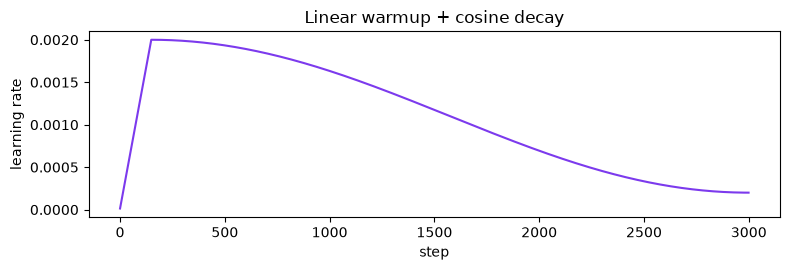

In [16]:
def learning_rate(step, max_steps, max_lr, warmup_steps, min_lr):
    if step < warmup_steps:
        return max_lr * (step + 1) / warmup_steps
    progress = (step - warmup_steps) / max(1, max_steps - warmup_steps)
    return min_lr + 0.5 * (max_lr - min_lr) * (1 + math.cos(math.pi * progress))


steps = np.arange(3000)
plt.figure(figsize=(8, 2.8))
plt.plot(steps, [learning_rate(s, 3000, 2e-3, 150, 2e-4) for s in steps], color="#7c3aed")
plt.xlabel("step")
plt.ylabel("learning rate")
plt.title("Linear warmup + cosine decay")
plt.tight_layout()
plt.show()

### 7e. The training loop

Everything comes together here: random mini-batches, forward and backward passes, the optimizer step, periodic evaluation on the full training and validation sets, and **checkpointing** the parameters with the best validation loss.

In [17]:
def evaluate(logits_fn, params, X, Y, batch_size=4096):
    total = 0.0
    for start in range(0, len(X), batch_size):
        xb, yb = X[start:start + batch_size], Y[start:start + batch_size]
        total += mean_cross_entropy(logits_fn(params, xb), yb) * len(yb)
    return total / len(X)


def train(loss_and_grads, logits_fn, params, data, steps=3000, batch_size=64, max_lr=2e-3,
          min_lr=2e-4, warmup_steps=150, weight_decay=0.1, eval_every=100, seed=0, verbose=True):
    X_tr, Y_tr, X_va, Y_va = data
    batch_rng = np.random.default_rng(seed)
    optimizer = AdamW(params, weight_decay=weight_decay)
    history = []
    best = {"val_loss": math.inf, "step": None, "params": None}
    start_time = time.perf_counter()

    for step in range(steps):
        idx = batch_rng.integers(0, len(X_tr), size=batch_size)
        loss, grads = loss_and_grads(params, X_tr[idx], Y_tr[idx])
        lr = learning_rate(step, steps, max_lr, warmup_steps, min_lr)
        optimizer.step(params, grads, lr)

        if step % eval_every == 0 or step == steps - 1:
            train_loss = evaluate(logits_fn, params, X_tr, Y_tr)
            val_loss = evaluate(logits_fn, params, X_va, Y_va)
            history.append({"step": step, "batch_loss": loss, "train_loss": train_loss,
                            "val_loss": val_loss, "lr": lr})
            if val_loss < best["val_loss"]:          # checkpoint the best model so far
                best = {"val_loss": val_loss, "step": step,
                        "params": {k: v.copy() for k, v in params.items()}}
            if verbose and step % (eval_every * 5) == 0:
                print(f"step {step:5d} | lr {lr:.2e} | train {train_loss:.4f} | val {val_loss:.4f}")

    elapsed = time.perf_counter() - start_time
    if verbose:
        print(f"done in {elapsed:.1f}s | best val loss {best['val_loss']:.4f} at step {best['step']}")
    return pd.DataFrame(history), best


data = (X_train, Y_train, X_val, Y_val)
mlp_params = init_mlp(config, np.random.default_rng(SEED))
mlp_history, mlp_best = train(mlp_loss_and_grads, mlp_logits, mlp_params, data, seed=SEED)

step     0 | lr 1.33e-05 | train 3.4405 | val 3.4396
step   500 | lr 1.93e-03 | train 1.7252 | val 1.9978
step  1000 | lr 1.63e-03 | train 1.3583 | val 1.8643
step  1500 | lr 1.17e-03 | train 1.1361 | val 1.8615
step  2000 | lr 6.94e-04 | train 1.0130 | val 1.8726
step  2500 | lr 3.33e-04 | train 0.9465 | val 1.8737
done in 3.8s | best val loss 1.8474 at step 1900

We train the neural bigram baseline the same way, using the same optimizer and schedule.

In [18]:
bigram_params = {"W": np.zeros((V, V))}   # all-zero logits = exactly uniform predictions
bigram_history, bigram_best = train(bigram_loss_and_grads, bigram_logits, bigram_params, data,
                                    max_lr=3e-2, min_lr=3e-3, weight_decay=0.0, seed=SEED, verbose=False)
print(f"Bigram: best val loss {bigram_best['val_loss']:.4f} at step {bigram_best['step']}")

Bigram: best val loss 2.2413 at step 600

### Loss curves

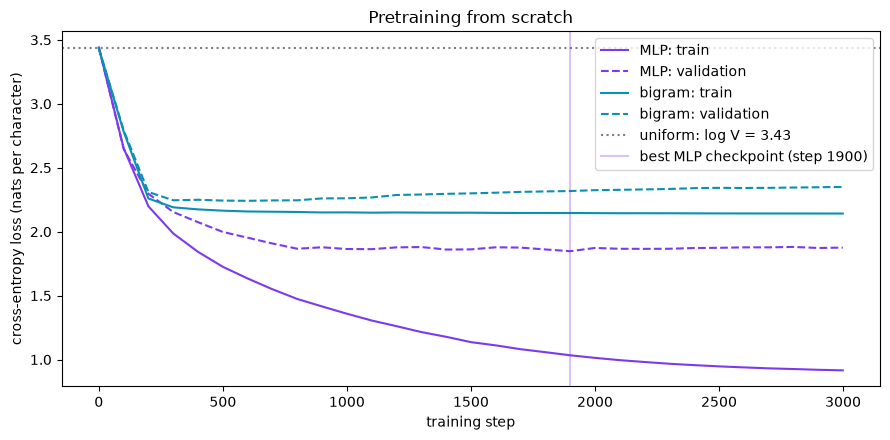

In [19]:
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(mlp_history["step"], mlp_history["train_loss"], color="#7c3aed", label="MLP: train")
ax.plot(mlp_history["step"], mlp_history["val_loss"], color="#7c3aed", linestyle="--", label="MLP: validation")
ax.plot(bigram_history["step"], bigram_history["train_loss"], color="#0891b2", label="bigram: train")
ax.plot(bigram_history["step"], bigram_history["val_loss"], color="#0891b2", linestyle="--", label="bigram: validation")
ax.axhline(math.log(V), color="gray", linestyle=":", label=f"uniform: log V = {math.log(V):.2f}")
ax.axvline(mlp_best["step"], color="#7c3aed", alpha=0.3, label=f"best MLP checkpoint (step {mlp_best['step']})")
ax.set_xlabel("training step")
ax.set_ylabel("cross-entropy loss (nats per character)")
ax.set_title("Pretraining from scratch")
ax.legend()
plt.tight_layout()
plt.show()

How to read this plot:

- Both models start at $\log V$, the uniform prediction, just as the initialization section predicted.
- The **bigram** model learns quickly and then plateaus. One character of context only gets it so far.
- The **MLP** keeps improving on the training set long after the validation loss stops improving. The widening gap is **overfitting**: with more parameters than examples, the model starts memorizing the training paragraphs. That is why we kept the **best validation checkpoint** rather than the final weights.

## 8. Evaluation

### 8a. Loss and perplexity against baselines

A loss number means little on its own, so we compare it against baselines:

- **Uniform**: knows nothing, perplexity $= V$.
- **Count-based bigram** with add-$k$ smoothing: the model from notebook 00, estimated by counting.
- **Neural bigram**: the same information, learned by gradient descent.
- **MLP**: 6 characters of context.

In [20]:
def count_bigram_val_loss(k=0.1):
    counts = np.zeros((V, V))
    np.add.at(counts, (X_train[:, -1], Y_train), 1)
    probs = (counts + k) / (counts + k).sum(axis=1, keepdims=True)
    return float(-np.log(probs[X_val[:, -1], Y_val]).mean()), float(-np.log(probs[X_train[:, -1], Y_train]).mean())


count_val, count_train = count_bigram_val_loss()
final_mlp = mlp_best["params"]

results = pd.DataFrame([
    ("uniform", math.log(V), math.log(V), 0),
    ("count bigram (add-0.1)", count_train, count_val, V * V),
    ("neural bigram", evaluate(bigram_logits, bigram_best["params"], X_train, Y_train), bigram_best["val_loss"], V * V),
    ("MLP, context 6", evaluate(mlp_logits, final_mlp, X_train, Y_train), mlp_best["val_loss"], sum(param_breakdown.values())),
], columns=["model", "train loss", "val loss", "parameters"])
results["val perplexity"] = np.exp(results["val loss"])
results["val bits / char"] = results["val loss"] / math.log(2)
display(results.set_index("model"))

,train loss,val loss,parameters,val perplexity,val bits / char
model,,,,,
uniform,3.4340,3.4340,0,31.0000,4.9542
count bigram (add-0.1),2.1503,2.2295,961,9.2950,3.2165
neural bigram,2.1579,2.2413,961,9.4054,3.2335
"MLP, context 6",1.0334,1.8474,16911,6.3431,2.6652


The neural bigram converges to almost exactly the same validation loss as the count-based bigram. That makes sense: with the same information, gradient descent rediscovers the counts.

The MLP gets well below both, because it uses **more context**. Perplexity makes this concrete: it went from $V$ (guessing blindly among every character) to choosing among only a handful of plausible next characters.

**Bits per character** is the same loss measured in base 2 instead of base $e$. It is the standard unit for character-level models, and it relates directly to compression: a model with $b$ bits/char could compress text to about $b/8$ of its original size.

### 8b. What does the model generate?

Loss is the primary metric, but we should always **look at samples**.

In [21]:
def sample_text(params, cfg, tokenizer, rng, prompt="", max_chars=220, temperature=0.8, top_k=None):
    context = [tokenizer.eot_id] * cfg.context_length + tokenizer.encode(prompt)
    generated = []
    for _ in range(max_chars):
        x = np.array(context[-cfg.context_length:])[None, :]
        logits = mlp_logits(params, x)[0] / temperature
        if top_k is not None:
            cutoff = np.sort(logits)[-top_k]
            logits = np.where(logits < cutoff, -np.inf, logits)
        probs = np.exp(log_softmax(logits))
        next_id = int(rng.choice(len(probs), p=probs))
        if next_id == tokenizer.eot_id:
            break
        context.append(next_id)
        generated.append(next_id)
    return prompt + tokenizer.decode(generated)


untrained = init_mlp(config, np.random.default_rng(0))
gen_rng = np.random.default_rng(7)

print("UNTRAINED (random weights):")
print("  ", sample_text(untrained, config, tokenizer, gen_rng, max_chars=120))
print("\nTRAINED (best checkpoint), temperature 0.8:")
for _ in range(3):
    print("  ", sample_text(final_mlp, config, tokenizer, gen_rng))

UNTRAINED (random weights):
   nvsbdv

TRAINED (best checkpoint), temperature 0.8:
   the sealowees in a low shalk igs brgy tee the millowes re ther pith round their leacs of caant ear, darnt s soles the ground is muntil sres foweres the caye mome water its arky wace each and unto lichts in the water on s
   the sur and the sea.
   the seain.

The untrained model produces uniform noise. The trained model has learned, **from nothing but next-character prediction**:

- the spelling of common words, and that words are separated by spaces
- short multi-word phrases, and punctuation followed by a space
- when to end a document (by generating `<eot>`)

With only 6 characters of context and a few kilobytes of data, it can't keep a coherent thought across a sentence. Fixing that requires more context, more data and a better architecture, which is exactly what the rest of this repository builds.

## 9. Analyze and improve

Real SLM development is a loop: **train → evaluate → analyze → change one thing → retrain**. Let's run one experiment and one error analysis.

### 9a. Experiment: how much context helps?

We retrain the MLP with different context lengths, keeping everything else fixed.

,parameters,train loss,best val loss,best step
context length,,,,
1,6671,2.1751,2.2346,2200
2,8719,1.6683,1.8796,2600
4,12815,1.2612,1.7759,1900
8,21007,1.3765,1.9203,800
12,29199,1.1842,2.0792,800
16,37391,1.4800,2.2247,500


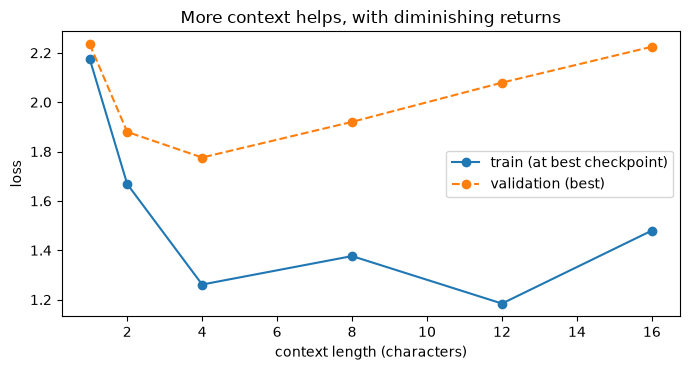

In [22]:
sweep_rows = []
for k in [1, 2, 4, 8, 12, 16]:
    cfg_k = ModelConfig(vocab_size=V, context_length=k)
    Xtr_k, Ytr_k = make_examples(train_stream, k, tokenizer.eot_id)
    Xva_k, Yva_k = make_examples(val_stream, k, tokenizer.eot_id)
    params_k = init_mlp(cfg_k, np.random.default_rng(SEED))
    _, best_k = train(mlp_loss_and_grads, mlp_logits, params_k, (Xtr_k, Ytr_k, Xva_k, Yva_k),
                      seed=SEED, verbose=False)
    sweep_rows.append({
        "context length": k,
        "parameters": sum(count_parameters(cfg_k).values()),
        "train loss": evaluate(mlp_logits, best_k["params"], Xtr_k, Ytr_k),
        "best val loss": best_k["val_loss"],
        "best step": best_k["step"],
    })

sweep = pd.DataFrame(sweep_rows).set_index("context length")
display(sweep)

plt.figure(figsize=(7, 3.8))
plt.plot(sweep.index, sweep["train loss"], "o-", label="train (at best checkpoint)")
plt.plot(sweep.index, sweep["best val loss"], "o--", label="validation (best)")
plt.xlabel("context length (characters)")
plt.ylabel("loss")
plt.title("More context helps, with diminishing returns")
plt.legend()
plt.tight_layout()
plt.show()

Going from 1 to a few characters of context helps a lot: the model can now complete words it has started. Beyond about 4 characters, validation loss gets *worse*, and the best checkpoint arrives earlier and earlier because overfitting sets in sooner. Longer windows add parameters ($k \cdot d \cdot H$ grows with $k$) and give the model more ways to memorize, but our tiny dataset doesn't contain enough *patterns* to make use of them.

This is a central lesson in model design: **architecture capacity, context length and data size must grow together**. A Transformer handles long contexts far more efficiently than a fixed window: attention's parameter count doesn't grow with the context length at all.

### 9b. Error analysis: which characters are hard?

Average loss hides a lot. Let's break the validation loss down by the **type of character being predicted**.

In [23]:
def char_class(token_id):
    if token_id == tokenizer.eot_id:
        return "<eot>"
    ch = tokenizer.id_to_token[token_id]
    if ch == " ":
        return "space"
    if ch in "aeiou":
        return "vowel"
    if ch.isalpha():
        return "consonant"
    return "punctuation"


val_log_probs = log_softmax(mlp_logits(final_mlp, X_val))
per_token_loss = -val_log_probs[np.arange(len(Y_val)), Y_val]

# Is this the first character of a word? (previous char is a space or the start of a document)
starts_word = np.isin(X_val[:, -1], [tokenizer.token_to_id[" "], tokenizer.eot_id])

analysis = pd.DataFrame({
    "class": [char_class(t) for t in Y_val],
    "position": np.where(starts_word, "first letter of a word", "inside a word / after a letter"),
    "loss": per_token_loss,
})

display(analysis.groupby("class")["loss"].agg(["count", "mean"]).sort_values("mean", ascending=False))
display(analysis[analysis["class"].isin(["vowel", "consonant"])]
        .groupby("position")["loss"].agg(["count", "mean"]))

,count,mean
class,,
punctuation,16,3.9951
consonant,370,2.1811
vowel,208,1.9786
<eot>,5,1.8622
space,138,0.5051


,count,mean
position,,
first letter of a word,143,2.8241
inside a word / after a letter,435,1.8729


The pattern is clear, and it matches intuition:

- **The first letter of a word is hard.** Choosing which word comes next is a decision about *meaning*, and 6 characters of context carry little meaning.
- **Letters inside a word are easy.** Once a word has started, its spelling is largely determined.
- **Spaces are the easiest of all**: once a word is complete, a space almost always follows.
- **Punctuation is the hardest class.** Deciding *where a sentence ends* is, again, a decision about meaning. It is also rare, so the model sees few examples of it.

So the remaining loss is mostly about **choosing words**, not spelling them. Subword tokenization (Module 01) and long-range attention (Module 03) target exactly this.

## 10. Optional post-training: fine-tuning on a new domain

**Pretraining** builds general knowledge from a broad corpus. **Post-training** adapts the pretrained model. Instruction tuning, chat formatting and preference optimization are all post-training. Mechanically, the simplest form, **fine-tuning**, is just *more training*: the same loss on new, targeted data, usually with a smaller learning rate.

Our pretraining corpus never mentions volcanoes. Let's fine-tune on two short volcano paragraphs, then measure two things:

- loss on a **held-out** volcano paragraph (did the model adapt?)
- loss on the **original** validation set (did it forget what it knew?)

In [24]:
volcano_train = [clean_text(t) for t in [
    "A volcano is an opening in the ground where hot melted rock rises from deep inside the earth. When the pressure grows too great, the volcano erupts.",
    "Melted rock is called magma while it is underground and lava once it pours out of a volcano. As lava cools, it hardens into new rock.",
]]
volcano_heldout = [clean_text(
    "Some volcanoes erupt with great force and throw ash high into the sky, while others pour out rivers of lava that flow slowly down their sides."
)]

Xft, Yft = make_examples(build_stream(volcano_train, tokenizer), CONTEXT_LENGTH, tokenizer.eot_id)
Xft_val, Yft_val = make_examples(build_stream(volcano_heldout, tokenizer), CONTEXT_LENGTH, tokenizer.eot_id)


def report(params, label):
    return {
        "model": label,
        "volcano train loss": evaluate(mlp_logits, params, Xft, Yft),
        "volcano held-out loss": evaluate(mlp_logits, params, Xft_val, Yft_val),
        "original val loss": evaluate(mlp_logits, params, X_val, Y_val),
    }


ft_rows = [report(final_mlp, "pretrained")]
for ft_steps in [100, 400]:
    ft_params = {k: v.copy() for k, v in final_mlp.items()}
    train(mlp_loss_and_grads, mlp_logits, ft_params, (Xft, Yft, Xft_val, Yft_val), steps=ft_steps,
          batch_size=32, max_lr=1e-3, min_lr=1e-4, warmup_steps=10, eval_every=50, verbose=False)
    ft_rows.append(report(ft_params, f"fine-tuned {ft_steps} steps"))

display(pd.DataFrame(ft_rows).set_index("model"))
print("Sample after 400 fine-tuning steps, prompt 'the volcano':")
print("  ", sample_text(ft_params, config, tokenizer, np.random.default_rng(3), prompt="the volcano", max_chars=150))

,volcano train loss,volcano held-out loss,original val loss
model,,,
pretrained,2.3010,2.1502,1.8474
fine-tuned 100 steps,1.2159,2.0340,1.9383
fine-tuned 400 steps,0.3116,2.2339,2.2943


Sample after 400 fine-tuning steps, prompt 'the volcano':
   the volcano erungd warms ow rocas it lighin oillin oock it pelatd.

Fine-tuning drives the loss on the volcano training text down quickly, and the generations shift toward the new vocabulary. But look at the other columns:

- The **held-out** volcano paragraph improves only a little after 100 steps, then gets *worse* again by 400 steps. Two paragraphs teach the model *those two paragraphs* more than they teach it "volcano text". Fine-tuning can overfit too, and it needs its own validation set.
- Loss on the **original** validation set gets worse as fine-tuning continues. This is **catastrophic forgetting**: the new data overwrites what was learned before.

Real post-training fights forgetting with smaller learning rates, fewer steps, mixing in some pretraining data, and parameter-efficient methods such as LoRA. **This repository focuses on pretraining from scratch**; post-training appears only where it helps us understand the pretrained model.

## 11. Inference and deployment

A trained model is only useful once it can be **saved, loaded and run efficiently**.

### 11a. Decoding strategies

Notebook 00 introduced temperature. **Top-k sampling** adds another control: sample only from the $k$ most likely tokens, so the model never picks something absurd from the long tail of the distribution.

In [25]:
decode_rng = np.random.default_rng(11)
for temperature, top_k in [(0.2, None), (0.8, None), (0.8, 5), (1.5, None)]:
    label = f"T={temperature}" + (f", top-k={top_k}" if top_k else "")
    print(f"{label:16} ", sample_text(final_mlp, config, tokenizer, decode_rng,
                                       prompt="the ", max_chars=110, temperature=temperature, top_k=top_k))

T=0.2             the sea.
T=0.8             the ther kor drows water cor shes ao the moun a water leain the mart sild the laye, and the sorls ol the oiv is th
T=0.8, top-k=5    the son da the pallem out and senthe water is the water that rount, farm witer sher unt rack rich, begs dery wark 
T=1.5             the slils. mowa foa, for, its treundd stsaesss on coor, wardt, bnid noess.ongag th light andeas aof bimith j lee, 

### 11b. Save and reload: the model as an artifact

A deployable model is more than weights. It needs:

- the **weights**
- the **architecture config**, to rebuild the model
- the **tokenizer vocabulary**, because the model is useless with a different tokenizer

We write all three to disk, reload them into a fresh model, and check that it produces **exactly** the same logits. The files go in a temporary directory so the repository stays clean.

In [26]:
export_dir = Path(tempfile.mkdtemp(prefix="tiny_slm_"))

np.savez(export_dir / "weights.npz", **final_mlp)
(export_dir / "config.json").write_text(json.dumps(asdict(config), indent=2))
(export_dir / "tokenizer.json").write_text(json.dumps({"id_to_token": tokenizer.id_to_token}, ensure_ascii=False))

# --- later, possibly on another machine ---
loaded_config = ModelConfig(**json.loads((export_dir / "config.json").read_text()))
with np.load(export_dir / "weights.npz") as f:
    loaded_params = {k: f[k] for k in f.files}
loaded_vocab = json.loads((export_dir / "tokenizer.json").read_text())["id_to_token"]

assert loaded_vocab == tokenizer.id_to_token
same = np.array_equal(mlp_logits(loaded_params, X_val), mlp_logits(final_mlp, X_val))
print("Reloaded model reproduces logits exactly:", same)
for p in sorted(export_dir.iterdir()):
    print(f"  {p.name:15} {p.stat().st_size:>8,} bytes")

Reloaded model reproduces logits exactly: True
  config.json           86 bytes
  tokenizer.json       180 bytes
  weights.npz      136,488 bytes

### 11c. Quantization: smaller weights, (almost) the same model

Our weights are stored as 64-bit floats. **Quantization** stores them with fewer bits. In **symmetric per-tensor int8 quantization**, each weight matrix gets one scale factor:

$$
s = \frac{\max |W|}{127}, \qquad W_q = \operatorname{round}\!\left(\frac{W}{s}\right) \in \{-127, \ldots, 127\}, \qquad \hat W = s\, W_q
$$

We quantize the three weight matrices and keep the small bias vectors in full precision, which is a common choice.

In [27]:
def quantize_int8(W):
    scale = np.abs(W).max() / 127.0
    return np.round(W / scale).astype(np.int8), scale


def dequantize(Wq, scale):
    return Wq.astype(np.float64) * scale


quantized, scales = {}, {}
for name, value in final_mlp.items():
    if value.ndim == 2:
        quantized[name], scales[name] = quantize_int8(value)

dequantized = {k: (dequantize(quantized[k], scales[k]) if k in quantized else v) for k, v in final_mlp.items()}

bytes_fp64 = sum(v.nbytes for v in final_mlp.values())
bytes_fp32 = bytes_fp64 // 2
bytes_int8 = sum(q.nbytes for q in quantized.values()) + sum(v.nbytes // 2 for k, v in final_mlp.items() if k not in quantized)

quant_table = pd.DataFrame([
    ("float64 (as trained)", bytes_fp64, mlp_best["val_loss"]),
    ("float32", bytes_fp32, evaluate(mlp_logits, {k: v.astype(np.float32) for k, v in final_mlp.items()}, X_val, Y_val)),
    ("int8 weights", bytes_int8, evaluate(mlp_logits, dequantized, X_val, Y_val)),
], columns=["format", "bytes", "val loss"])
quant_table["size vs float32"] = (quant_table["bytes"] / bytes_fp32).map("{:.2f}x".format)
display(quant_table.set_index("format"))

worst = max(np.abs(final_mlp[k] - dequantized[k]).max() for k in quantized)
print(f"Largest absolute weight error after int8 round trip: {worst:.5f}")

,bytes,val loss,size vs float32
format,,,
float64 (as trained),135288,1.8474,2.00x
float32,67644,1.8474,1.00x
int8 weights,17388,1.8468,0.26x


Largest absolute weight error after int8 round trip: 0.01286

The int8 weights take about **a quarter of the float32 memory**, and the validation loss barely moves. For an SLM headed to a phone or a laptop, that's the difference between fitting and not fitting. Module 09 goes further: per-channel scales, int4, and the accuracy/size trade-off at real scale.

### 11d. Throughput

How fast is our model? Characters per second during generation is one of the numbers that matters most in deployment.

In [28]:
n_chars = 2000
context = [tokenizer.eot_id] * config.context_length
bench_rng = np.random.default_rng(0)

start = time.perf_counter()
for _ in range(n_chars):
    logits = mlp_logits(final_mlp, np.array(context[-config.context_length:])[None, :])[0]
    probs = np.exp(log_softmax(logits))
    context.append(int(bench_rng.choice(V, p=probs)))
elapsed = time.perf_counter() - start

print(f"Generated {n_chars} characters in {elapsed:.3f}s  ->  {n_chars / elapsed:,.0f} chars/sec (one CPU core, NumPy)")
print(f"Forward pass cost: about {2 * sum(param_breakdown.values()) / 1e3:.0f} KFLOPs per character (≈ 2N)")

Generated 2000 characters in 0.146s  ->  13,744 chars/sec (one CPU core, NumPy)
Forward pass cost: about 34 KFLOPs per character (≈ 2N)

Exact numbers depend on your machine. Notice that each character requires its own forward pass. Generation is **sequential**, while training processes a whole batch of positions in parallel. That asymmetry is why inference optimizations such as the **KV cache** (Module 09) and fast kernels (Module 07) matter so much.

## 12. Recap: the lifecycle, and where each stage goes next

| # | Stage | What we did here | At real SLM scale | Module |
|:-:|:--|:--|:--|:-:|
| 1 | Data collection | 44 hand-written documents from 3 "sources" | Billions of tokens from licensed and curated sources | 02 |
| 2 | Preprocessing | Regex cleaning, NFKC, 3 heuristic filters, SHA-256 + shingle Jaccard dedup | Language ID, classifier-based quality filters, MinHash-LSH dedup, PII removal | 02 |
| 3 | Tokenization | Character-level, `<eot>` and `<unk>` special tokens | Byte-level BPE with tens of thousands of tokens | 01 |
| 4 | Tokenized dataset | Sliding-window (context, target) pairs, split by document | Packed sequences in sharded binary files, streamed during training | 02, 05 |
| 5 | Architecture | Fixed-window MLP, about 17K parameters | Decoder-only Transformer, RoPE, RMSNorm, SwiGLU, GQA | 03, 04 |
| 6 | Initialization | Small output weights, so the initial loss is about $\log V$ | Scaled initialization for deep residual stacks | 04 |
| 7 | Pretraining | Hand-written backprop, gradient check, AdamW, warmup + cosine, best checkpoint | Autograd, mixed precision, gradient accumulation, `torch.compile`, GPUs | 05, 06 |
| 8 | Evaluation | Loss, perplexity, bits/char, baselines, samples | Validation loss and perplexity, downstream benchmarks | 08 |
| 9 | Analyze & improve | Context-length sweep, per-character-class error analysis | Ablations, scaling experiments | 08 |
| 10 | Post-training | Fine-tuning on new text; observed forgetting | SFT, preference optimization | (optional) |
| 11 | Inference & deployment | Temperature/top-k, save/load artifact, int8 quantization, throughput | KV cache, quantization, export, serving, Triton kernels | 07, 09 |

### Knowledge check

<details><summary><b>1. Why do we deduplicate <i>after</i> cleaning rather than before?</b></summary>

Cleaning maps superficially different copies (HTML, case, whitespace, curly quotes) to identical text. Cheap exact hashing then catches them, which leaves the expensive near-duplicate comparison for the few remaining cases.
</details>

<details><summary><b>2. Why split train and validation by document instead of by position in the text?</b></summary>

Halves of the same document share topic and phrasing, so validation text would be partly "seen" and the score optimistic. Document-level splits better measure generalization to genuinely new text.
</details>

<details><summary><b>3. What should the loss be right after initialization, and why?</b></summary>

About $\log V$, the loss of a uniform prediction. A higher value means the model starts confidently wrong, which wastes early training and can destabilize it.
</details>

<details><summary><b>4. What is the gradient of softmax cross-entropy with respect to the logits?</b></summary>

$\operatorname{softmax}(z) - \operatorname{onehot}(y)$, averaged over the batch.
</details>

<details><summary><b>5. Why run a gradient check, and why not use numerical gradients for training?</b></summary>

It catches bugs in a hand-written backward pass. Numerical gradients need two forward passes *per parameter*, which is far too slow for training.
</details>

<details><summary><b>6. Training loss keeps falling but validation loss rises. What is happening, and what did we do about it?</b></summary>

Overfitting: the model is memorizing the training data. We kept the checkpoint with the best validation loss. Weight decay and more data also help.
</details>

<details><summary><b>7. Why didn't longer context keep improving validation loss?</b></summary>

The tiny dataset doesn't contain enough longer-range patterns to learn, while the extra parameters make memorization easier. Capacity, context and data have to grow together.
</details>

<details><summary><b>8. What is catastrophic forgetting?</b></summary>

When training on new data degrades performance on what the model learned before, as the original validation loss showed after fine-tuning.
</details>

<details><summary><b>9. Why must the tokenizer be shipped with the model?</b></summary>

The model only understands token IDs. A different tokenizer maps text to different IDs, so the model's outputs would be meaningless.
</details>

### Module 00 complete

Across this folder you have seen what a language model *is* (00), what a Transformer *computes* (01), how text becomes training data (02–04), what the training objective *means* (05), how to train a model with PyTorch (06), and every stage of the lifecycle with nothing hidden (this notebook).

**Next: Module 01 · Tokenization in depth.** We scale the BPE tokenizer from notebook 02 to a real corpus: byte-level BPE, pre-tokenization, and how vocabulary size changes sequence length, the embedding parameter budget and what the model has to learn.